<a href="https://colab.research.google.com/github/adityarajput2045/Machine-Learning-Topics/blob/main/Simple_Linear_Regression_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt


In [80]:
#reading the data
#here we are loading the data from scikit learn
from sklearn.datasets import load_diabetes

In [6]:
diabetes = load_diabetes()

In [7]:
diabetes

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]]),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142., 155., 225.,  59

In [8]:
diabetes.data

array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
         0.01990749, -0.01764613],
       [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
        -0.06833155, -0.09220405],
       [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
         0.00286131, -0.02593034],
       ...,
       [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
        -0.04688253,  0.01549073],
       [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
         0.04452873, -0.02593034],
       [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
        -0.00422151,  0.00306441]])

In [9]:
diabetes.target

array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
        69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
        68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
        87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
       259.,  53., 190., 142.,  75., 142., 155., 225.,  59., 104., 182.,
       128.,  52.,  37., 170., 170.,  61., 144.,  52., 128.,  71., 163.,
       150.,  97., 160., 178.,  48., 270., 202., 111.,  85.,  42., 170.,
       200., 252., 113., 143.,  51.,  52., 210.,  65., 141.,  55., 134.,
        42., 111.,  98., 164.,  48.,  96.,  90., 162., 150., 279.,  92.,
        83., 128., 102., 302., 198.,  95.,  53., 134., 144., 232.,  81.,
       104.,  59., 246., 297., 258., 229., 275., 281., 179., 200., 200.,
       173., 180.,  84., 121., 161.,  99., 109., 115., 268., 274., 158.,
       107.,  83., 103., 272.,  85., 280., 336., 281., 118., 317., 235.,
        60., 174., 259., 178., 128.,  96., 126., 28

In [12]:
diabetes.feature_names

['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

In [14]:
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [19]:
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names )

In [20]:
df

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [22]:
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [23]:
df["target"] = diabetes.target

In [26]:
df

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
...,...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207,178.0
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485,104.0
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491,132.0
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930,220.0


In [81]:
#EDA, DATACLEANING, DATAPREPARATION, FEATURE ENGINEERING

In [25]:
#Linear Regression >> One independent variables, One dependent variables >> To undrestand the relationship between two variables.

In [49]:
x = df[["bmi"]]

In [50]:
x  # Independent Variables

,bmi
0,0.061696
1,-0.051474
2,0.044451
3,-0.011595
4,-0.036385
...,...
437,0.019662
438,-0.015906
439,-0.015906
440,0.039062


In [51]:
y = df["target"]

In [52]:
y # Dependent Varibles

,target
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0
...,...
437,178.0
438,104.0
439,132.0
440,220.0


In [53]:
# Train Test Split

In [54]:
from sklearn.model_selection import train_test_split

In [82]:
x_train, x_test, y_train, y_test =  train_test_split(x, y, test_size=0.2, random_state=2)
#reandom_state when fixed helps us to reproduce the same result again and again

In [56]:
x_train

,bmi
70,-0.069797
37,0.011039
170,-0.020218
400,0.045529
286,-0.054707
...,...
299,-0.013751
22,-0.004050
72,-0.004050
15,-0.018062


In [57]:
x_test

,bmi
212,0.003494
422,0.077863
67,-0.014828
89,-0.048241
390,0.069241
...,...
129,0.016428
417,0.071397
332,0.104809
150,0.070319


In [58]:
#Scaling >> Optional

In [59]:
from sklearn.linear_model import LinearRegression

In [60]:
model = LinearRegression()

In [61]:
model

LinearRegression()

In [83]:
# Train of model
#at the backend it will use gradient descent to give optimal coefficient

In [63]:
x_train

,bmi
70,-0.069797
37,0.011039
170,-0.020218
400,0.045529
286,-0.054707
...,...
299,-0.013751
22,-0.004050
72,-0.004050
15,-0.018062


In [64]:
y_train

,target
70,48.0
37,276.0
170,47.0
400,175.0
286,60.0
...,...
299,83.0
22,68.0
72,202.0
15,171.0


In [65]:
model.fit(x_train, y_train)

LinearRegression()

In [69]:
model.coef_   # coefficient << mx + c , where m = slop = coef_

array([974.48209999])

In [68]:
model.intercept_   # intercept << mx + c , where c = constant = intercept

np.float64(152.45404935855575)

In [70]:
y_pred = model.predict(x_test)

In [71]:
y_pred

array([155.8592353 , 228.33052685, 138.00398955, 105.44442379,
       219.92805826, 274.54410406,  94.94133806,  97.0419552 ,
       120.14874381, 210.4752811 , 153.75861815, 134.85306384,
       182.11694963, 151.65800101, 259.83978404, 121.19905238,
       190.51941821,  94.94133806, 127.50090382, 136.95368098,
       209.42497253, 222.02867541, 113.84689237, 164.26170388,
       132.75244669, 198.9218868 , 223.07898398, 128.5512124 ,
       113.84689237, 214.67651539, 235.68268686,  87.58917804,
        84.43825232, 120.14874381, 154.80892673, 161.11077816,
       171.6138639 , 168.46293818, 124.3499781 , 131.70213812,
       205.22373824, 128.5512124 , 206.27404681, 128.5512124 ,
       195.77096108, 140.1046067 , 173.71448104, 212.57589825,
       107.54504093, 159.01016102, 211.52558968, 205.22373824,
       156.90954387, 128.5512124 , 174.76478961, 122.24936096,
       114.89720095, 104.39411521, 136.95368098, 187.36849249,
       128.5512124 , 192.62003536, 144.30584099, 194.72

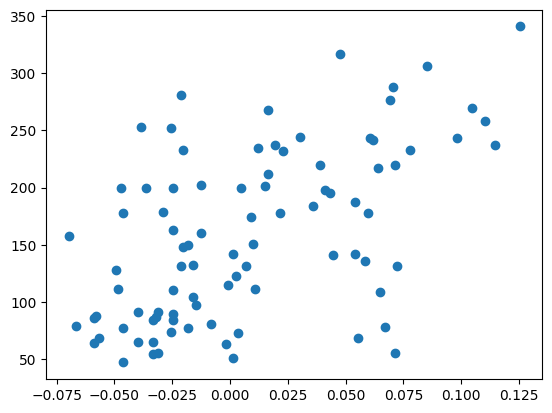

In [72]:
plt.scatter(x_test, y_test )

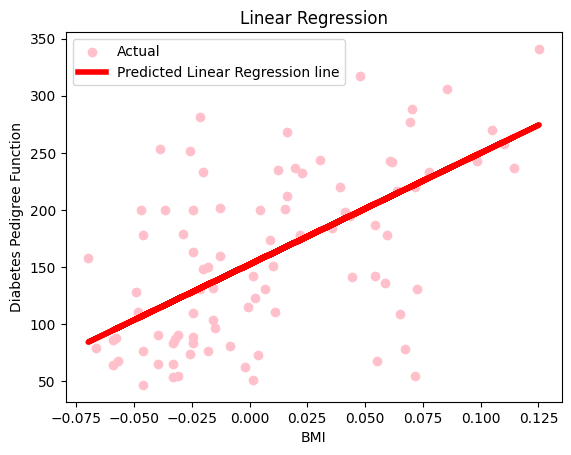

In [84]:
#visualise the result
plt.scatter(x_test, y_test, color="pink", label="Actual" )
plt.plot(x_test, y_pred, color="red" , linewidth=4, label="Predicted Linear Regression line")
plt.xlabel("BMI")
plt.ylabel("Diabetes Pedigree Function")
plt.title("Linear Regression")
plt.legend()
plt.show()

In [79]:
#model evaluation
from sklearn.metrics import mean_squared_error
mean_squared_error(y_test, y_pred)

3898.258609540553